# Cross-Correlation Analysis

This notebook:
- 

## Notebook Overview
This notebook explores cross-correlation functions (CCF) between ROMY and G-ring records and related dispersion behavior.

**Main workflow**
- Load ROMY/G-ring event configurations and traces.
- Compute broadband and/or band-limited cross-correlations.
- Inspect lag/envelope peaks and derived velocity trends.
- Visualize frequency-dependent CCF behavior.
- Save selected figures for interpretation.

In [34]:
import os
import glob
import numpy as np
import obspy
import matplotlib.pyplot as plt

from obspy import UTCDateTime
from obspy.signal.rotate import rotate_ne_rt
from sixdegrees import sixdegrees
from obspy.signal.cross_correlation import correlate
from scipy.signal import hilbert
from obspy.geodetics.base import gps2dist_azimuth


In [35]:
def plot_cross_correlation(ccross, date, comp, type="rotation"):

    scale = 1e9

    time1 = np.arange(0, len(ccross['data1']))/ccross['sampling_rate']
    time2 = np.arange(0, len(ccross['data2']))/ccross['sampling_rate']

    data1 = ccross['data1']
    data2 = ccross['data2']

    # Create figure with subplots
    fig, axes = plt.subplots(3, 1, figsize=(14, 8))
    fig.suptitle(f'Cross-Correlation Analysis: ROMY vs G-ring {comp} (Event: {date})', 
                fontsize=16, fontweight='bold', y=0.96)

    # Plot ROMY JZ waveform
    axes[0].plot(time1, data1*scale, 'tab:blue', linewidth=1.5, alpha=0.9, label=f'ROMY ({comp})')
    if type == "rotation":
        axes[0].set_ylabel('Rotation rate (nrad/s)', fontsize=14)
    else:
        axes[0].set_ylabel(r'Acceleration (nm/s$^2$)', fontsize=14)
    axes[0].grid(True, alpha=0.3, linestyle='--')
    axes[0].legend(loc='upper right', fontsize=12)
    axes[0].tick_params(labelsize=10)
    axes[0].set_xlabel('Time (s) from origin time', fontsize=14)
    axes[0].set_xlim(0, max(time1))

    # no scientific notation
    axes[0].ticklabel_format(style='plain', axis='y')

    # Plot Gring JZ waveform
    axes[1].plot(time2, data2*scale, 'tab:orange', linewidth=1.5, alpha=0.9, label=f'G-ring ({comp})')
    if type == "rotation":
        axes[1].set_ylabel('Rotation rate (nrad/s)', fontsize=14)
    else:
        axes[1].set_ylabel(r'Acceleration (nm/s$^2$)', fontsize=14)
    axes[1].grid(True, alpha=0.3, linestyle='--')
    axes[1].legend(loc='upper right', fontsize=12)
    axes[1].tick_params(labelsize=10)
    axes[1].set_xlabel('Time (s) from origin time', fontsize=14)
    axes[1].set_xlim(0, max(time2))
    
    # no scientific notation
    axes[1].ticklabel_format(style='plain', axis='y')

    # Plot cross-correlation
    lags = ccross['lags']
    correlation = ccross['correlation']
    max_cc = ccross['max_cc']
    max_lag = ccross['max_lag']

    axes[2].plot(lags, correlation, 'k-', linewidth=1.5, alpha=0.8, label=f'Maximum CC: {max_cc:.2f} at lag: {max_lag:.1f} s')
    axes[2].axvline(0, color='k', linestyle='--', linewidth=1.5, alpha=0.5)
    axes[2].set_xlabel('Lag time (s)', fontsize=14)
    axes[2].set_ylabel('Cross-correlation', fontsize=14)
    axes[2].grid(True, alpha=0.3, linestyle='--')
    axes[2].legend(loc='best', fontsize=12)
    axes[2].tick_params(labelsize=10)

    axes[2].set_ylim(-1, 1)
    # Set reasonable x-axis limits for cross-correlation
    axes[2].set_xlim(-500, 500)

    # Align x-axis labels
    for ax in axes:
        ax.ticklabel_format(style='scientific', axis='y', scilimits=(0, 0))
        ax.tick_params(labelsize=12)
        
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    plt.show()

    return fig

In [36]:
def compute_cross_correlation(
        data1: np.ndarray,
        data2: np.ndarray,
        sampling_rate: float = 1.0,
        shift = None,
    ):
    """Cross-correlate two arrays (ObsPy correlate, demean + normalize)."""
    min_len = min(len(data1), len(data2))
    data1 = np.asarray(data1[:min_len], dtype=float)
    data2 = np.asarray(data2[:min_len], dtype=float)

    if shift is None:
        shift = len(data1) // 2

    cc = correlate(data1, data2, shift=shift, demean=True, normalize=True)
    dt = 1.0 / sampling_rate
    lags = np.arange(-shift, shift + 1) * dt
    max_idx = int(np.argmax(cc))

    return {
        "lags": lags,
        "correlation": cc,
        "max_cc": float(cc[max_idx]),
        "max_lag": float(lags[max_idx]),
        "data1": data1,
        "data2": data2,
        "sampling_rate": sampling_rate,
    }


In [37]:
# Configuration
events_dir = './events'

# Select dates
dates = ["20240422", "20240815"]

# Set filter parameters
fmin = 0.01
fmax = 0.2

# component 
comp = 'JZ'

Found event:
Origin time: 2024-04-22T18:26:52.852000Z
Magnitude: 6.1 mww
Location: 23.714°N, 121.660°E
Depth: 9.0 km
Epicentral Distance: 9470.32 km
Epicentral Distance: 85.2°
Backazimuth: 59.40°
Found event:
Origin time: 2024-04-22T18:26:52.852000Z
Magnitude: 6.1 mww
Location: 23.714°N, 121.660°E
Depth: 9.0 km
Epicentral Distance: 9313.56 km
Epicentral Distance: 83.8°
Backazimuth: 60.64°
-> fetching XX.ROMY..BHZ data from mseed file
-> fetching XX.ROMY..BHN data from mseed file
-> fetching XX.ROMY..BHE data from mseed file
3 Trace(s) in Stream:
XX.ROMY..BHZ | 2024-04-22T18:34:58.990000Z - 2024-04-22T19:50:00.990000Z | 20.0 Hz, 90041 samples
XX.ROMY..BHN | 2024-04-22T18:34:58.990000Z - 2024-04-22T19:50:00.990000Z | 20.0 Hz, 90041 samples
XX.ROMY..BHE | 2024-04-22T18:34:58.990000Z - 2024-04-22T19:50:00.990000Z | 20.0 Hz, 90041 samples
-> fetching XX.ROMY..BJZ data from mseed file
-> fetching XX.ROMY..BJN data from mseed file
-> fetching XX.ROMY..BJE data from mseed file
3 Trace(s) in St

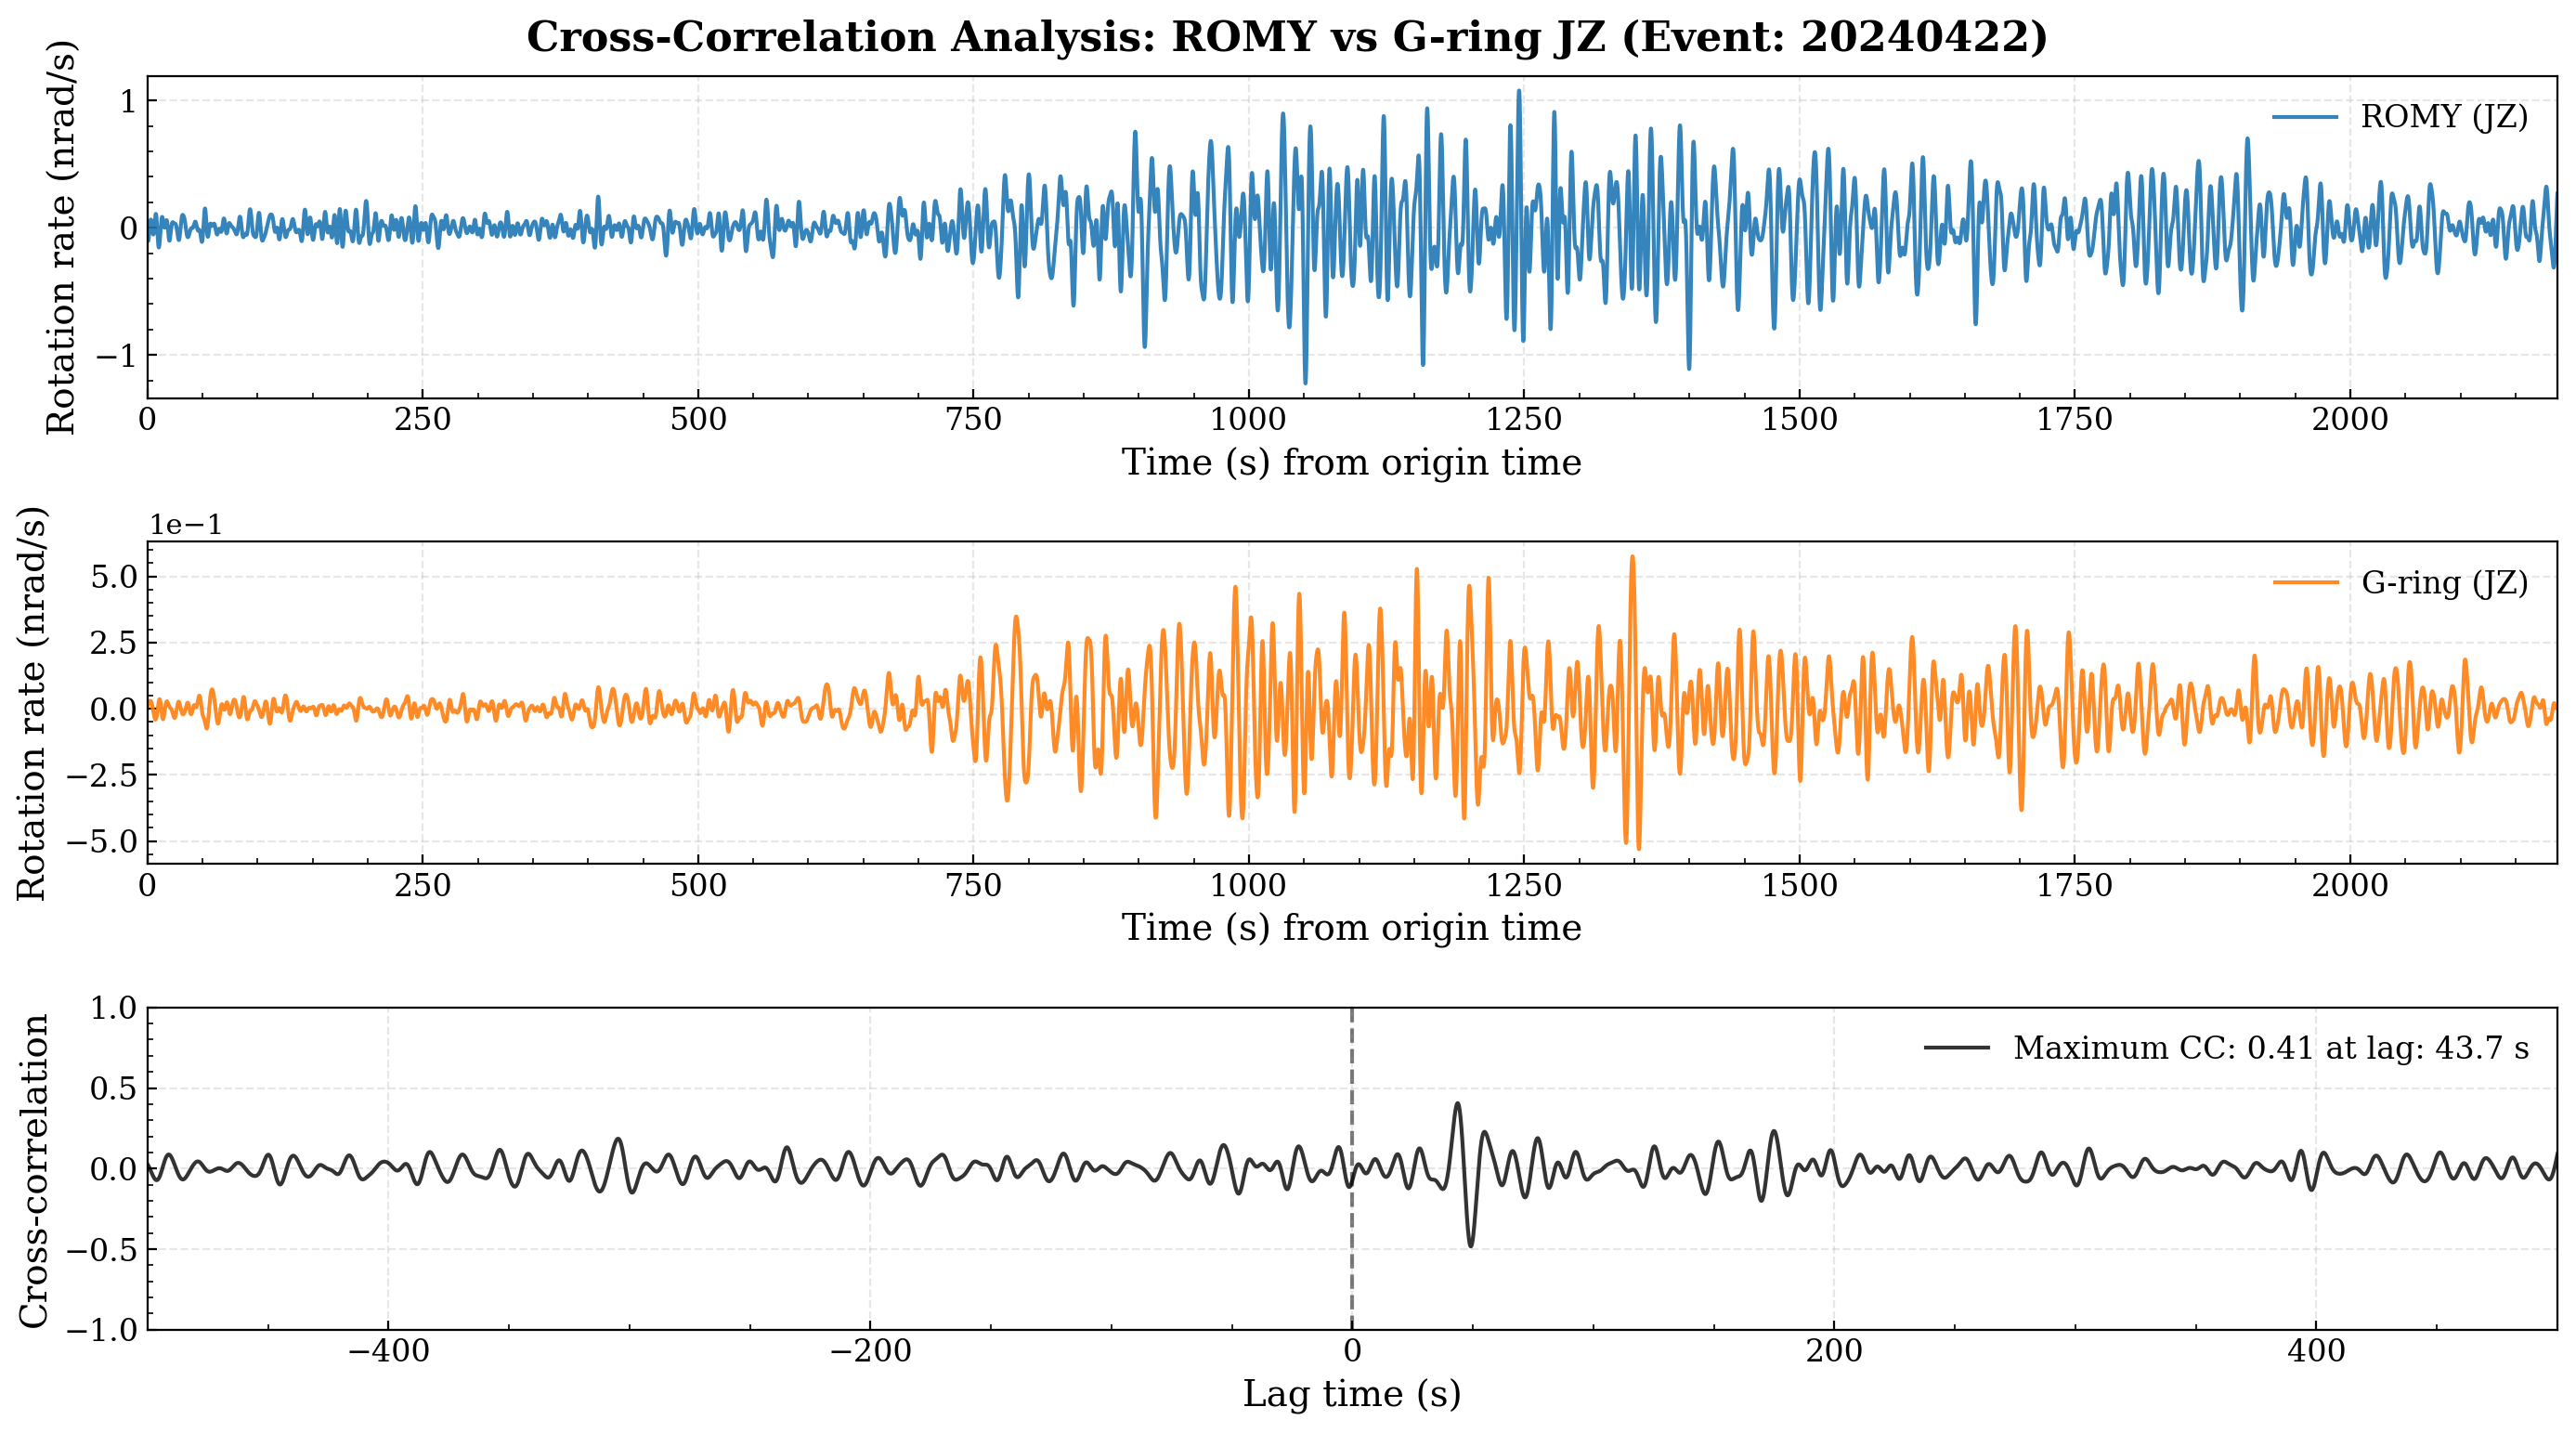

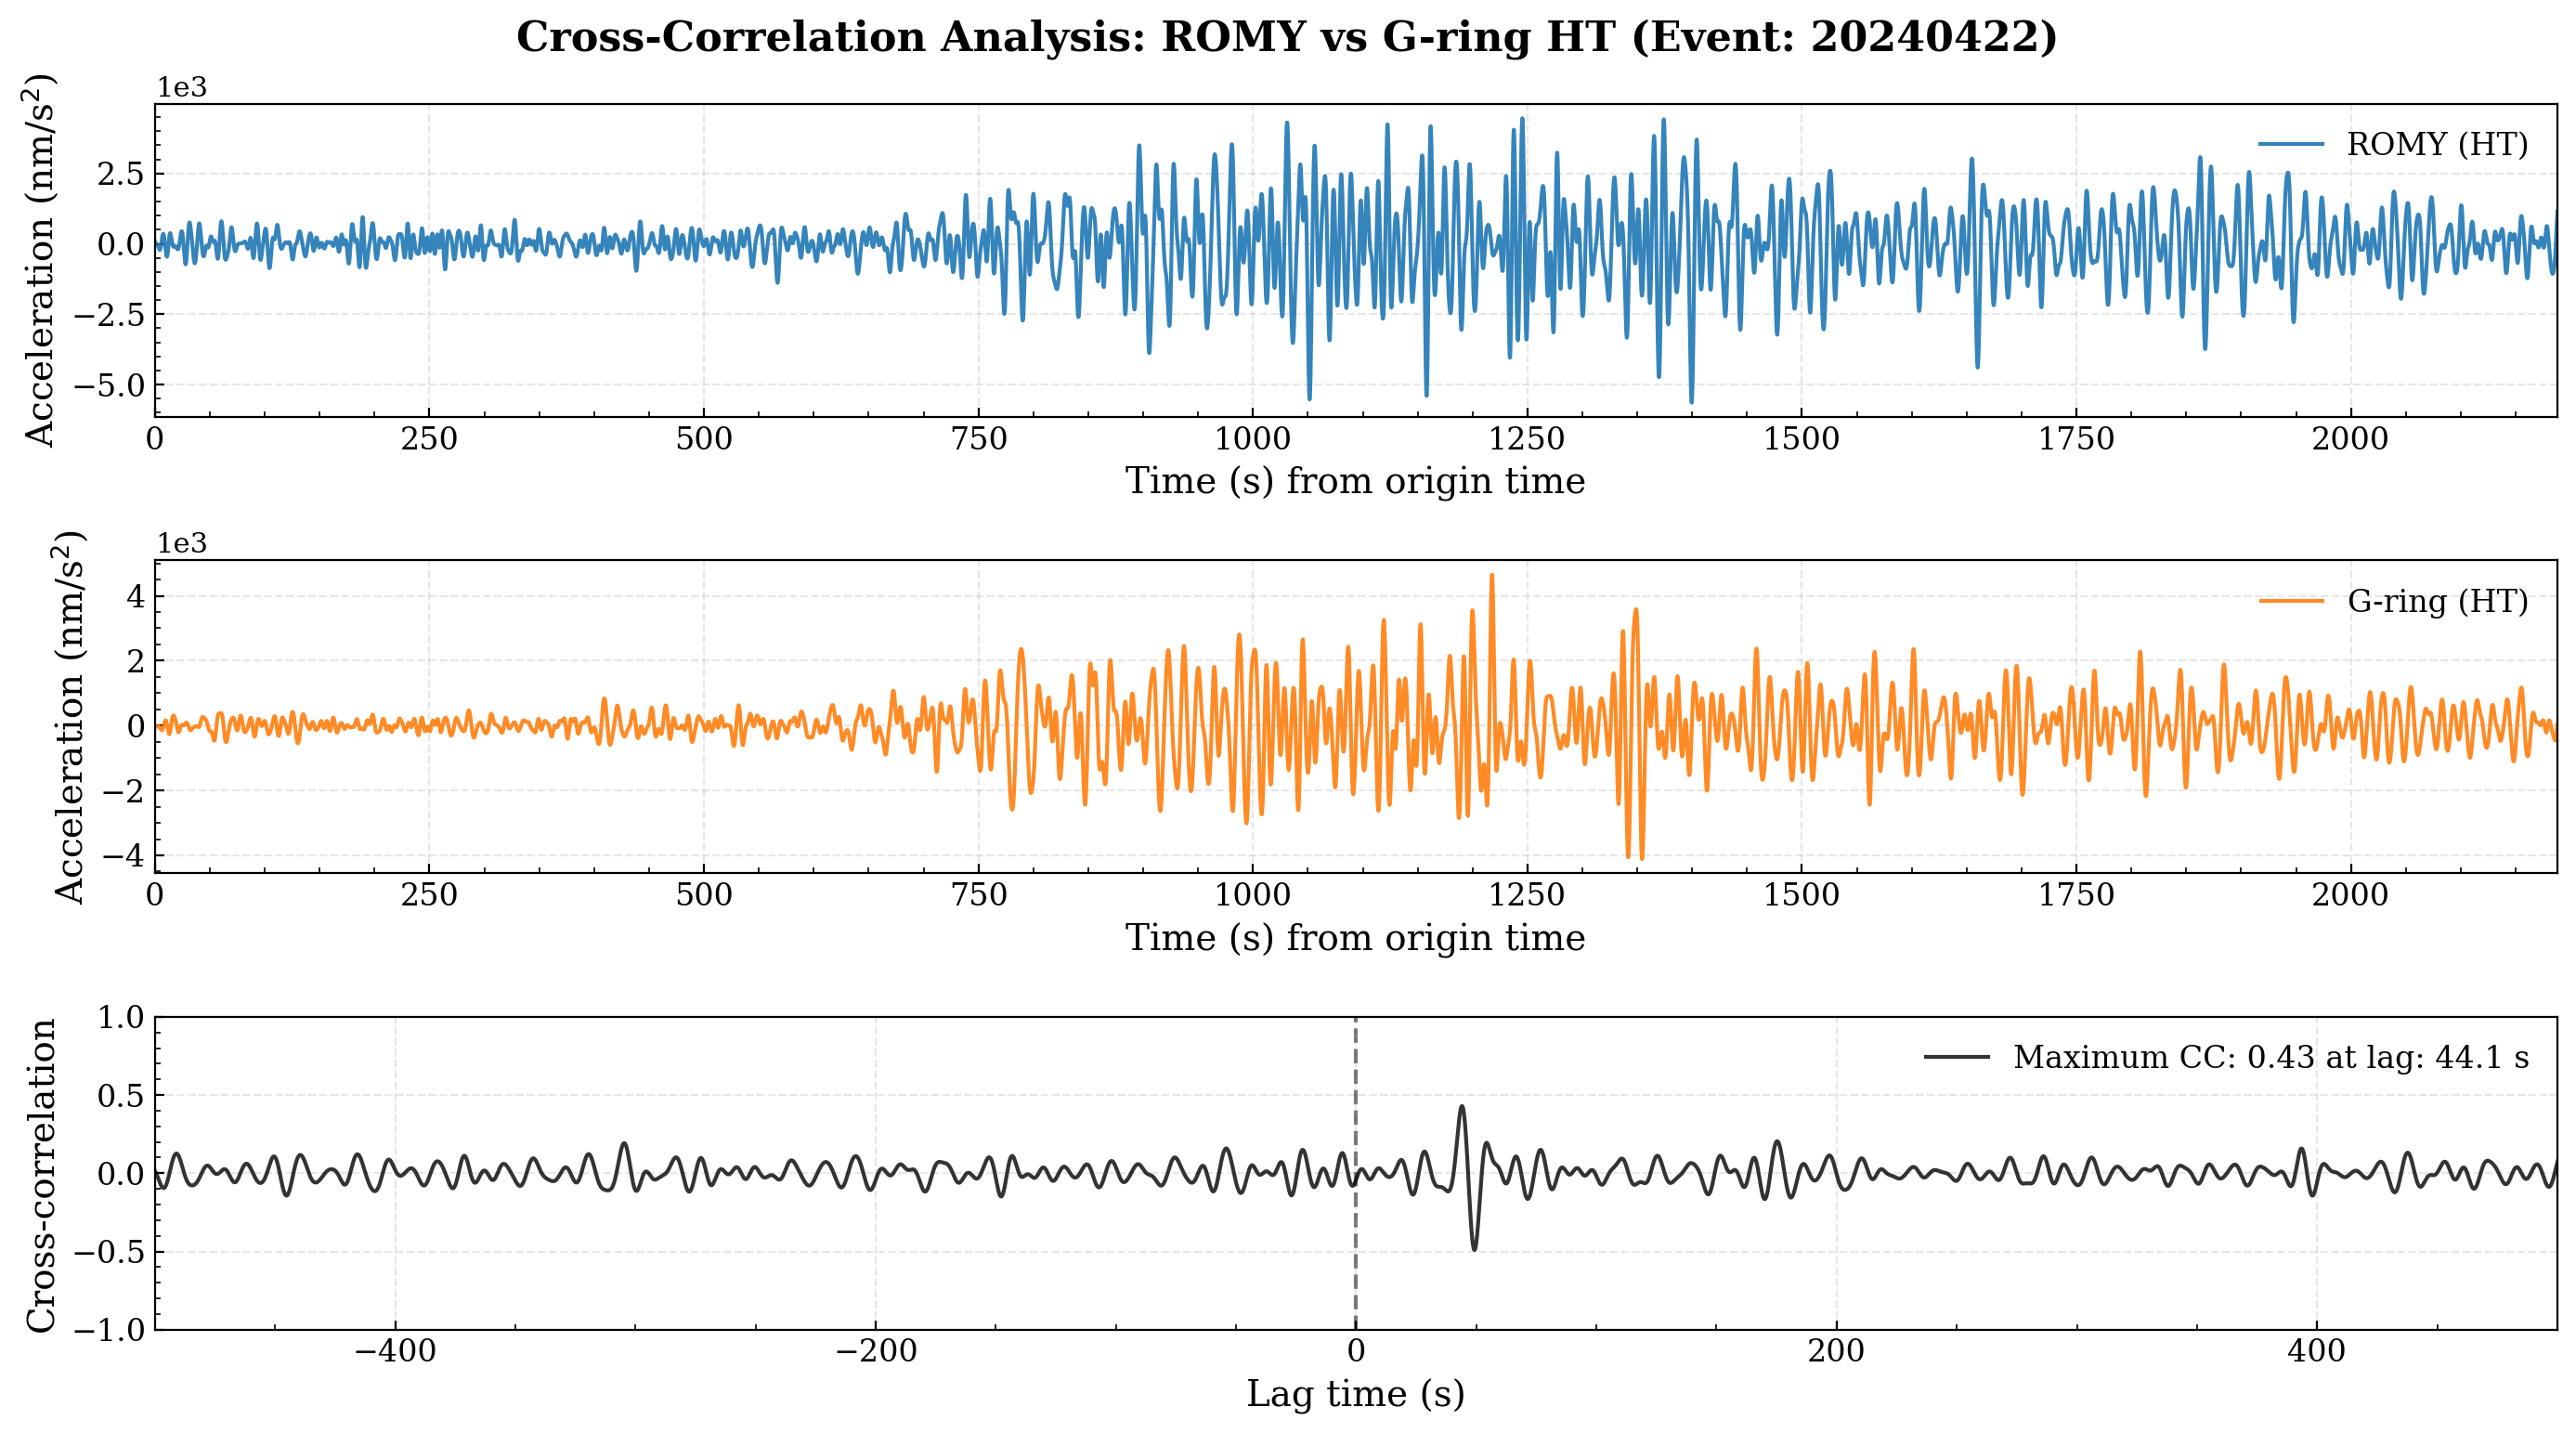

Found event:
Origin time: 2024-08-15T23:35:53.943000Z
Magnitude: 6.1 mww
Location: 23.749°N, 121.767°E
Depth: 14.0 km
Epicentral Distance: 9474.15 km
Epicentral Distance: 85.2°
Backazimuth: 59.31°
Found event:
Origin time: 2024-08-15T23:35:53.943000Z
Magnitude: 6.1 mww
Location: 23.749°N, 121.767°E
Depth: 14.0 km
Epicentral Distance: 9317.32 km
Epicentral Distance: 83.8°
Backazimuth: 60.54°
-> fetching XX.ROMY..BHZ data from mseed file
-> fetching XX.ROMY..BHN data from mseed file
-> fetching XX.ROMY..BHE data from mseed file
3 Trace(s) in Stream:
XX.ROMY..BHZ | 2024-08-15T23:44:58.989999Z - 2024-08-16T00:50:00.989999Z | 20.0 Hz, 78041 samples
XX.ROMY..BHN | 2024-08-15T23:44:58.989999Z - 2024-08-16T00:50:00.989999Z | 20.0 Hz, 78041 samples
XX.ROMY..BHE | 2024-08-15T23:44:58.989999Z - 2024-08-16T00:50:00.989999Z | 20.0 Hz, 78041 samples
-> fetching XX.ROMY..BJZ data from mseed file
-> fetching XX.ROMY..BJN data from mseed file
-> fetching XX.ROMY..BJE data from mseed file
3 Trace(s) in 

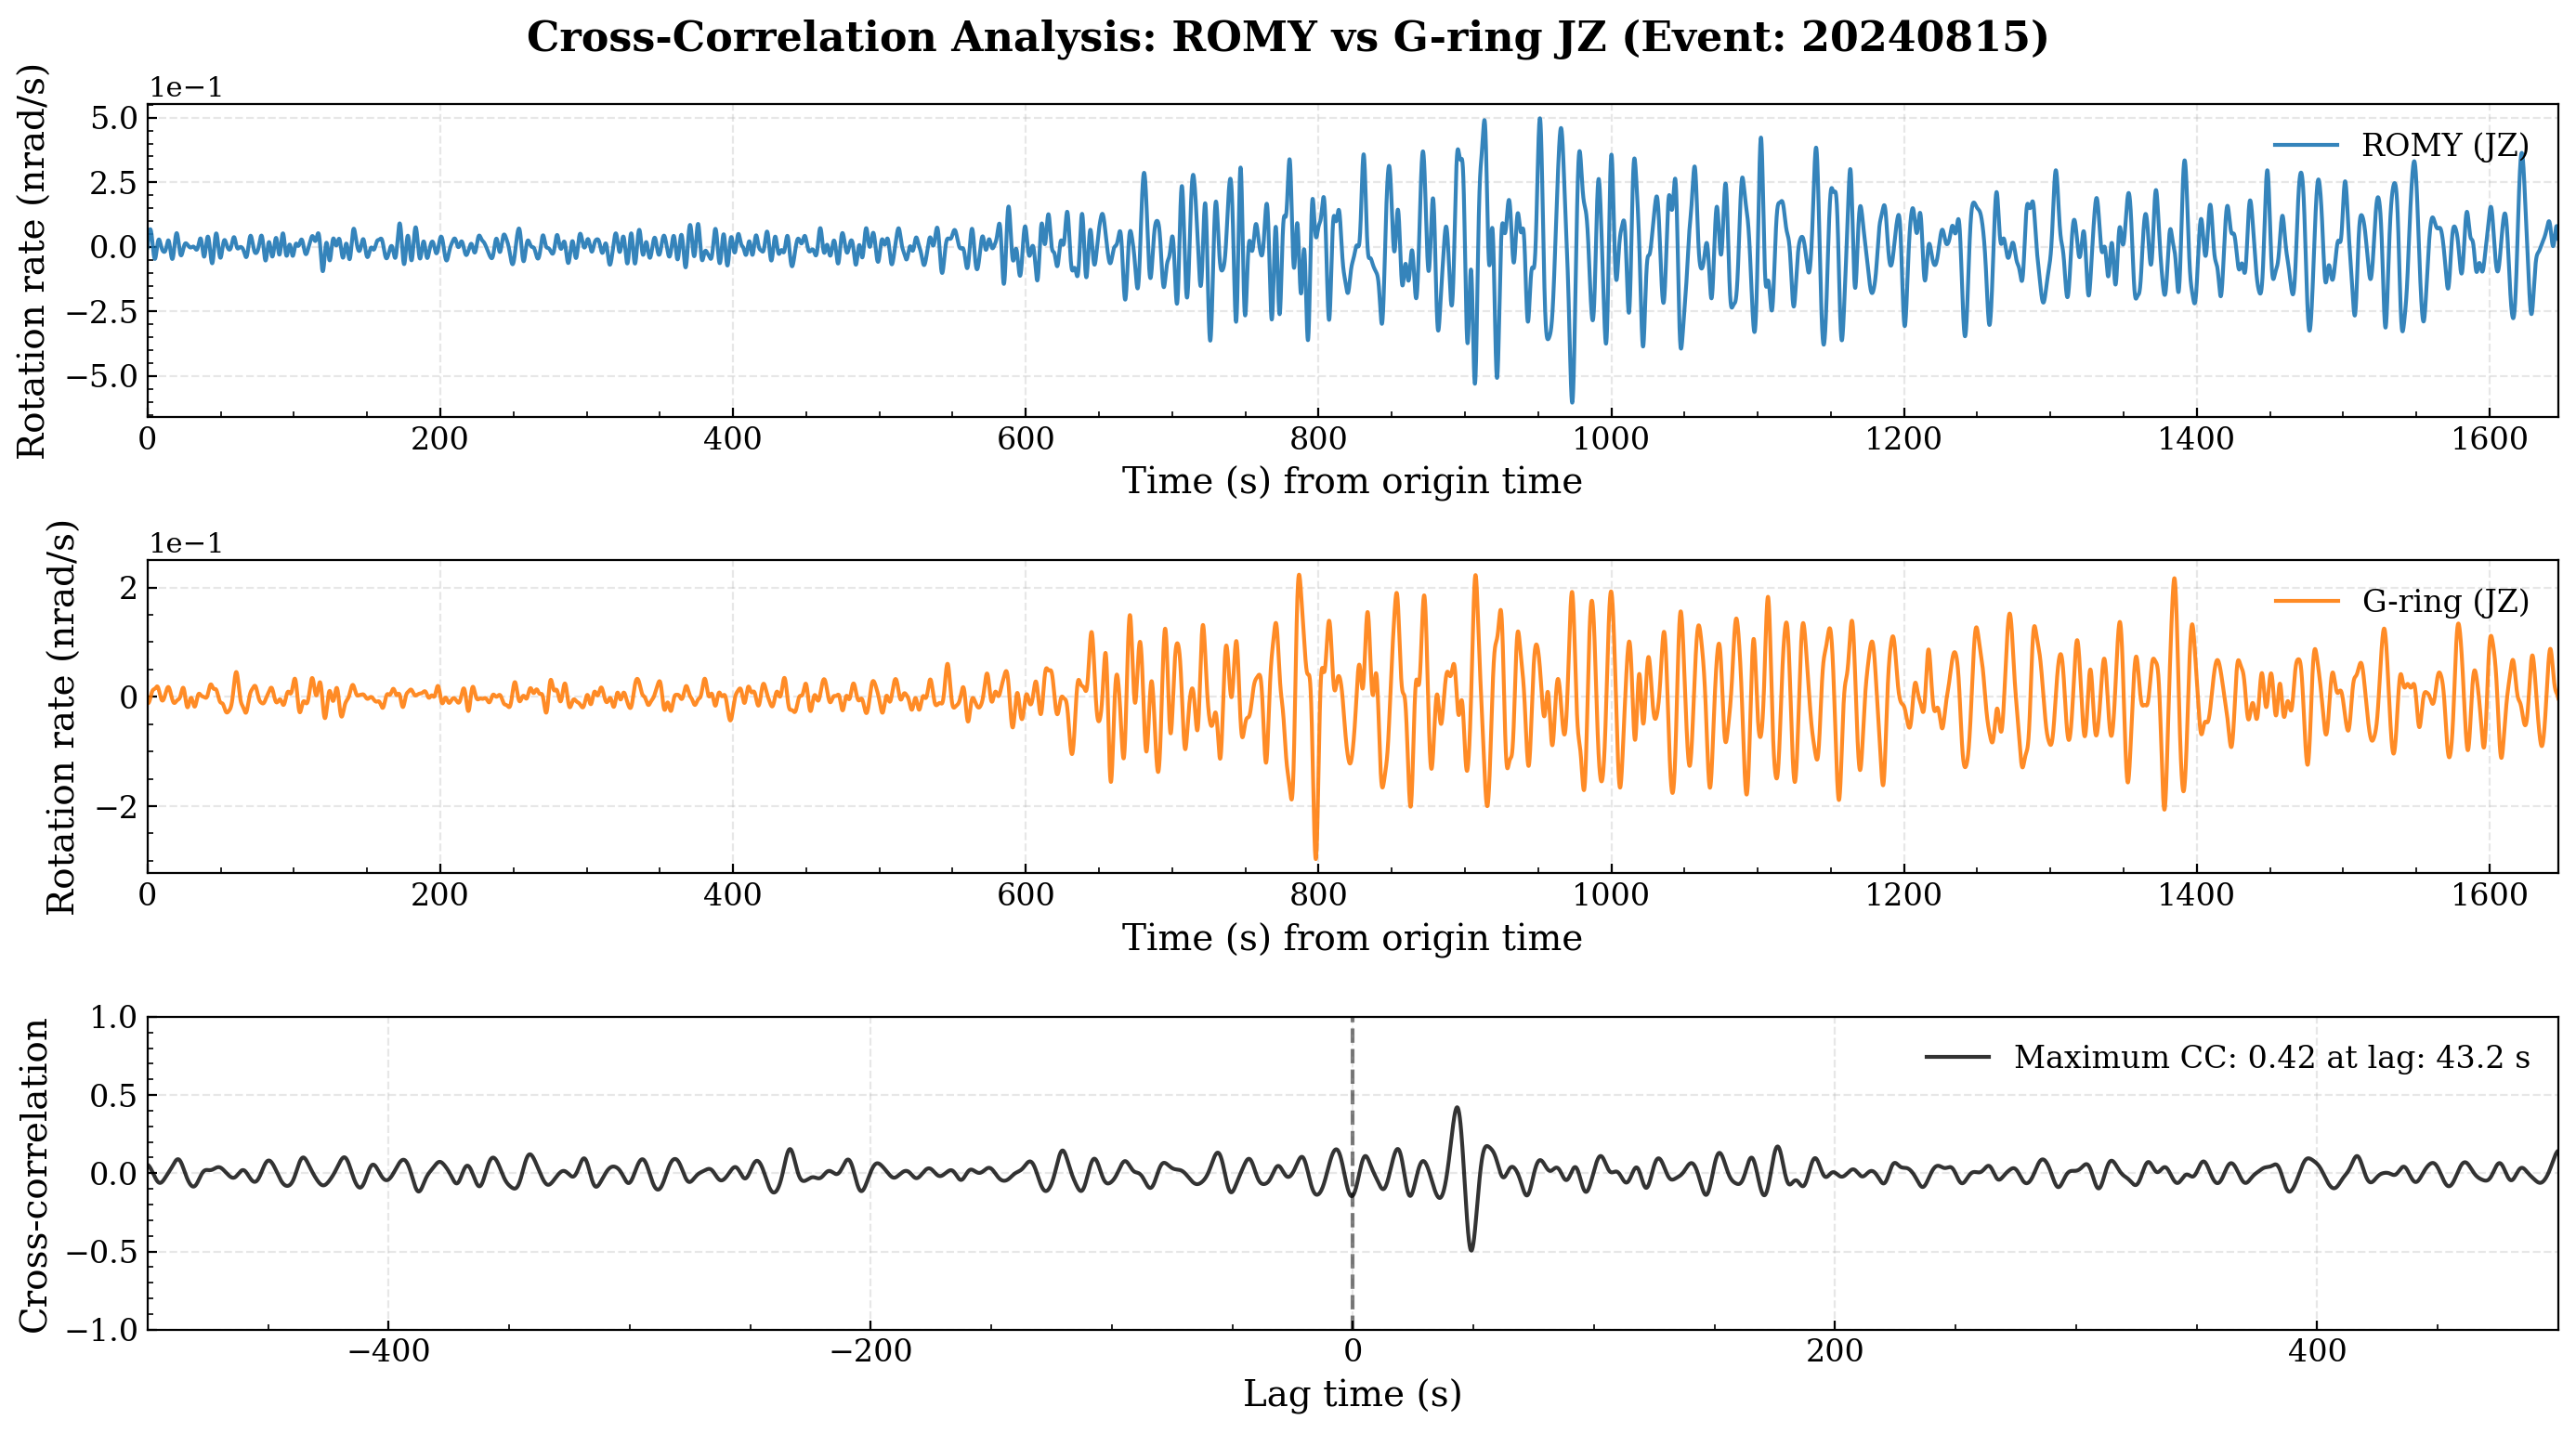

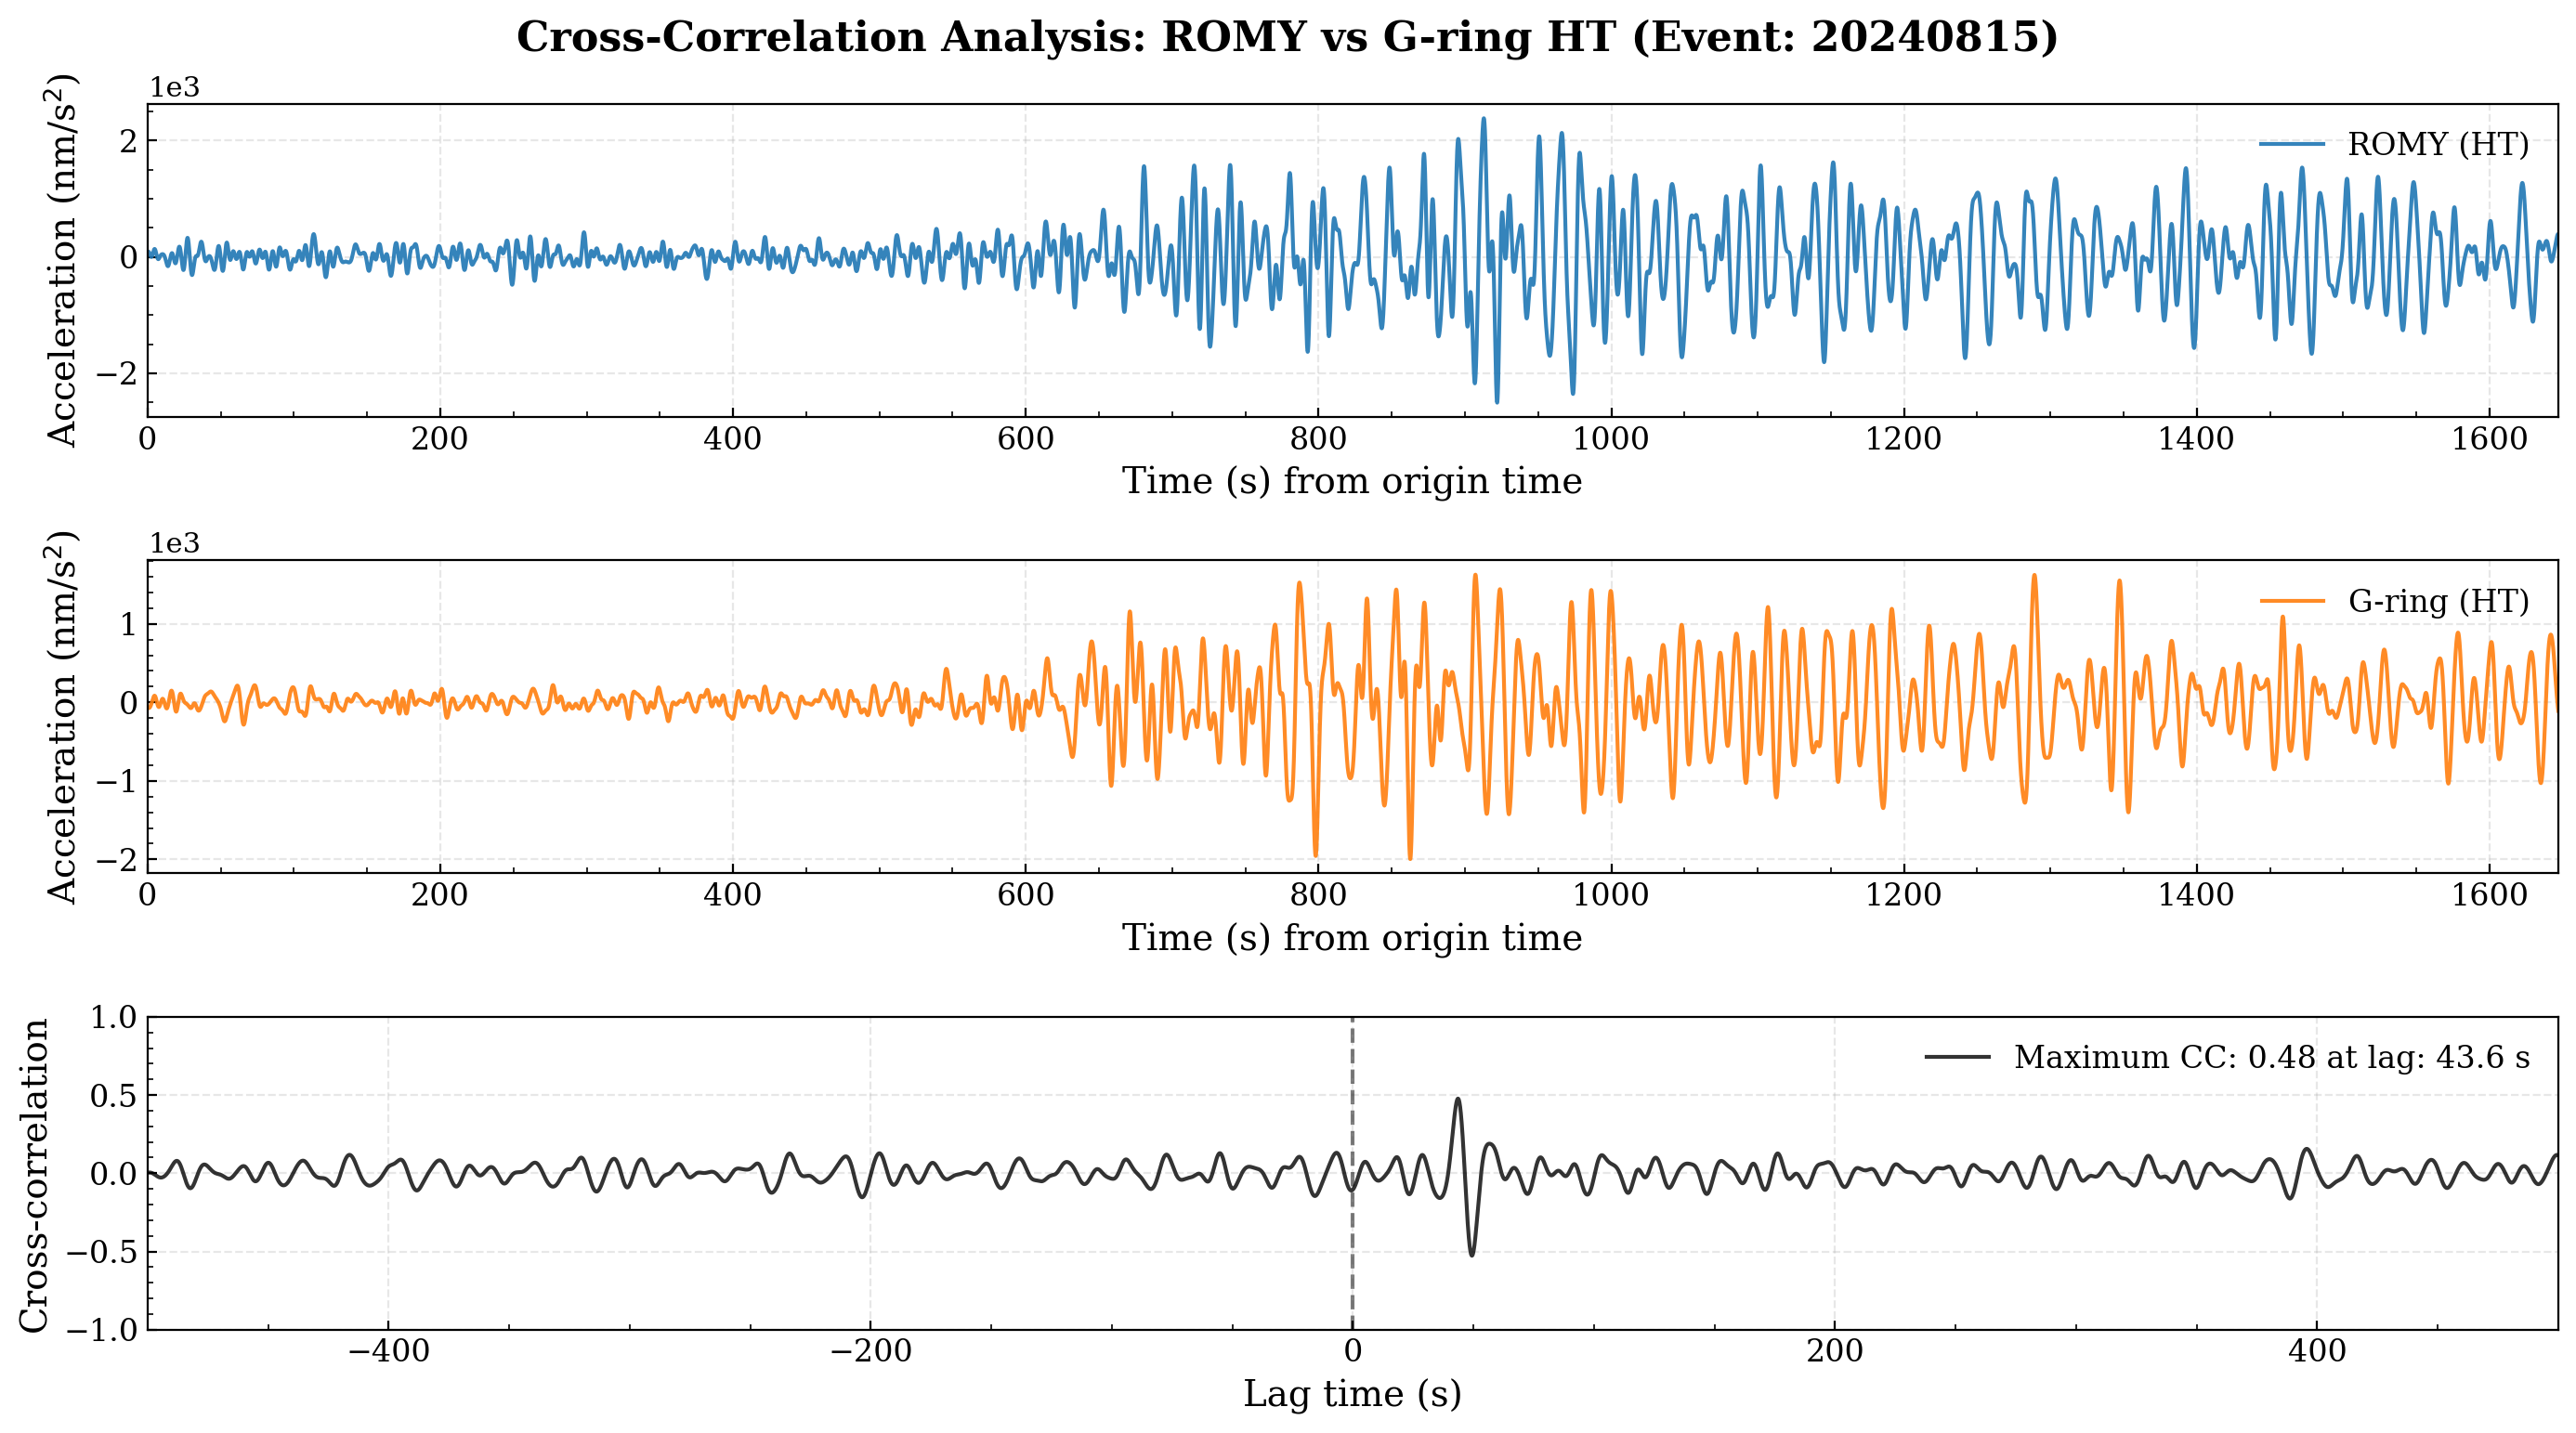

In [38]:
ccrossjz = {}
ccrossht = {}

for date in dates:

    configfile1 = events_dir + "/" + f"event_{date}" + "/" + f"config_romy_{date}"
    configfile2 = events_dir + "/" + f"event_{date}" + "/" + f"config_gring_{date}"

    config1 = sixdegrees.load_from_yaml(configfile1)
    config2 = sixdegrees.load_from_yaml(configfile2)

    sd1 = sixdegrees(config1)
    sd2 = sixdegrees(config2)

    ev1 = sd1.get_event_info(
        origin_time=config1['origin_time'],
        base_catalog="USGS",
        magnitude=config1['magnitude']
    )
    ev2 = sd2.get_event_info(
        origin_time=config2['origin_time'],
        base_catalog="USGS",
        magnitude=config2['magnitude']
    )

    sd1.load_data(config1['tbeg'], config1['tend'])
    sd2.load_data(config2['tbeg'], config2['tend'])

    # for tr in sd1.st:
    #     if tr.stats.channel[1] == "H":
    #         tr.integrate()

    # for tr in sd2.st:
    #     if tr.stats.channel[1] == "H":
    #         tr.integrate()

    sd1.filter_data(fmin=fmin, fmax=fmax)
    sd2.filter_data(fmin=fmin, fmax=fmax)

    sd1.trim(UTCDateTime(config1['origin_time'])+2000, UTCDateTime(config1['tend'])-800)
    sd2.trim(UTCDateTime(config2['origin_time'])+2000, UTCDateTime(config2['tend'])-800)

    # correlate JZ
    jz1 = sd1.st.select(channel=f"*{comp}")[0].data
    jz2 = sd2.st.select(channel=f"*{comp}")[0].data

    ccross_jz = compute_cross_correlation(jz1, jz2, sampling_rate=20)
    print(f"Maximum correlation: {ccross_jz['max_cc']:.4f} at lag: {ccross_jz['max_lag']:.2f} seconds")

    ccrossjz[date] = ccross_jz

    # correlate HT
    R1, T1 = rotate_ne_rt(
        sd1.st.select(channel=f"*HN")[0].data,
        sd1.st.select(channel=f"*HE")[0].data,
        ev1['backazimuth'])
    R2, T2 = rotate_ne_rt(
        sd2.st.select(channel=f"*HN")[0].data,
        sd2.st.select(channel=f"*HE")[0].data,
        ev2['backazimuth'])
    
    ccross_ht = compute_cross_correlation(T1, T2, sampling_rate=20)
    print(f"Maximum correlation: {ccross_ht['max_cc']:.4f} at lag: {ccross_ht['max_lag']:.2f} seconds")

    ccrossht[date] = ccross_ht

    fig = plot_cross_correlation(ccross_jz, date, "JZ", type="rotation")
    # fig.savefig(f'./output/figures/ccf/cross_correlation_romy_gring_jz_{date}.png', dpi=300)
    
    fig = plot_cross_correlation(ccross_ht, date, "HT", type="acceleration")
    # fig.savefig(f'./output/figures/ccf/cross_correlation_romy_gring_ht_{date}.png', dpi=300)

In [39]:
# Stack JZ and HT cross-correlations (±x samples around zero lag)
n1_jz = len(ccrossjz[dates[0]]['lags'])//2
n2_jz = len(ccrossjz[dates[1]]['lags'])//2
n1_ht = len(ccrossht[dates[0]]['lags'])//2
n2_ht = len(ccrossht[dates[1]]['lags'])//2
x = 10000

stack_jz = ccrossjz[dates[0]]['correlation'][n1_jz-x:n1_jz+x] + ccrossjz[dates[1]]['correlation'][n2_jz-x:n2_jz+x]
stack_ht = ccrossht[dates[0]]['correlation'][n1_ht-x:n1_ht+x] + ccrossht[dates[1]]['correlation'][n2_ht-x:n2_ht+x]

# distance between stations
dist, az, baz = gps2dist_azimuth(sd2.config['station_lat'], sd2.config['station_lon'], sd1.config['station_lat'], sd1.config['station_lon'])
dist_km = dist/1000

# Extract data for plotting JZ
lags1_jz = ccrossjz[dates[0]]['lags'][n1_jz-x:n1_jz+x]
lags2_jz = ccrossjz[dates[1]]['lags'][n2_jz-x:n2_jz+x]
cc1_jz = ccrossjz[dates[0]]['correlation'][n1_jz-x:n1_jz+x]
cc2_jz = ccrossjz[dates[1]]['correlation'][n2_jz-x:n2_jz+x]

# Extract data for plotting HT
lags1_ht = ccrossht[dates[0]]['lags'][n1_ht-x:n1_ht+x]
lags2_ht = ccrossht[dates[1]]['lags'][n2_ht-x:n2_ht+x]
cc1_ht = ccrossht[dates[0]]['correlation'][n1_ht-x:n1_ht+x]
cc2_ht = ccrossht[dates[1]]['correlation'][n2_ht-x:n2_ht+x]

# Product and cross-correlation of stacked JZ and HT CCFs
prod_stack_jz_ht = stack_jz * stack_ht
ccross_stack_jz_ht = compute_cross_correlation(stack_jz, stack_ht, sampling_rate=20)


# Plotting

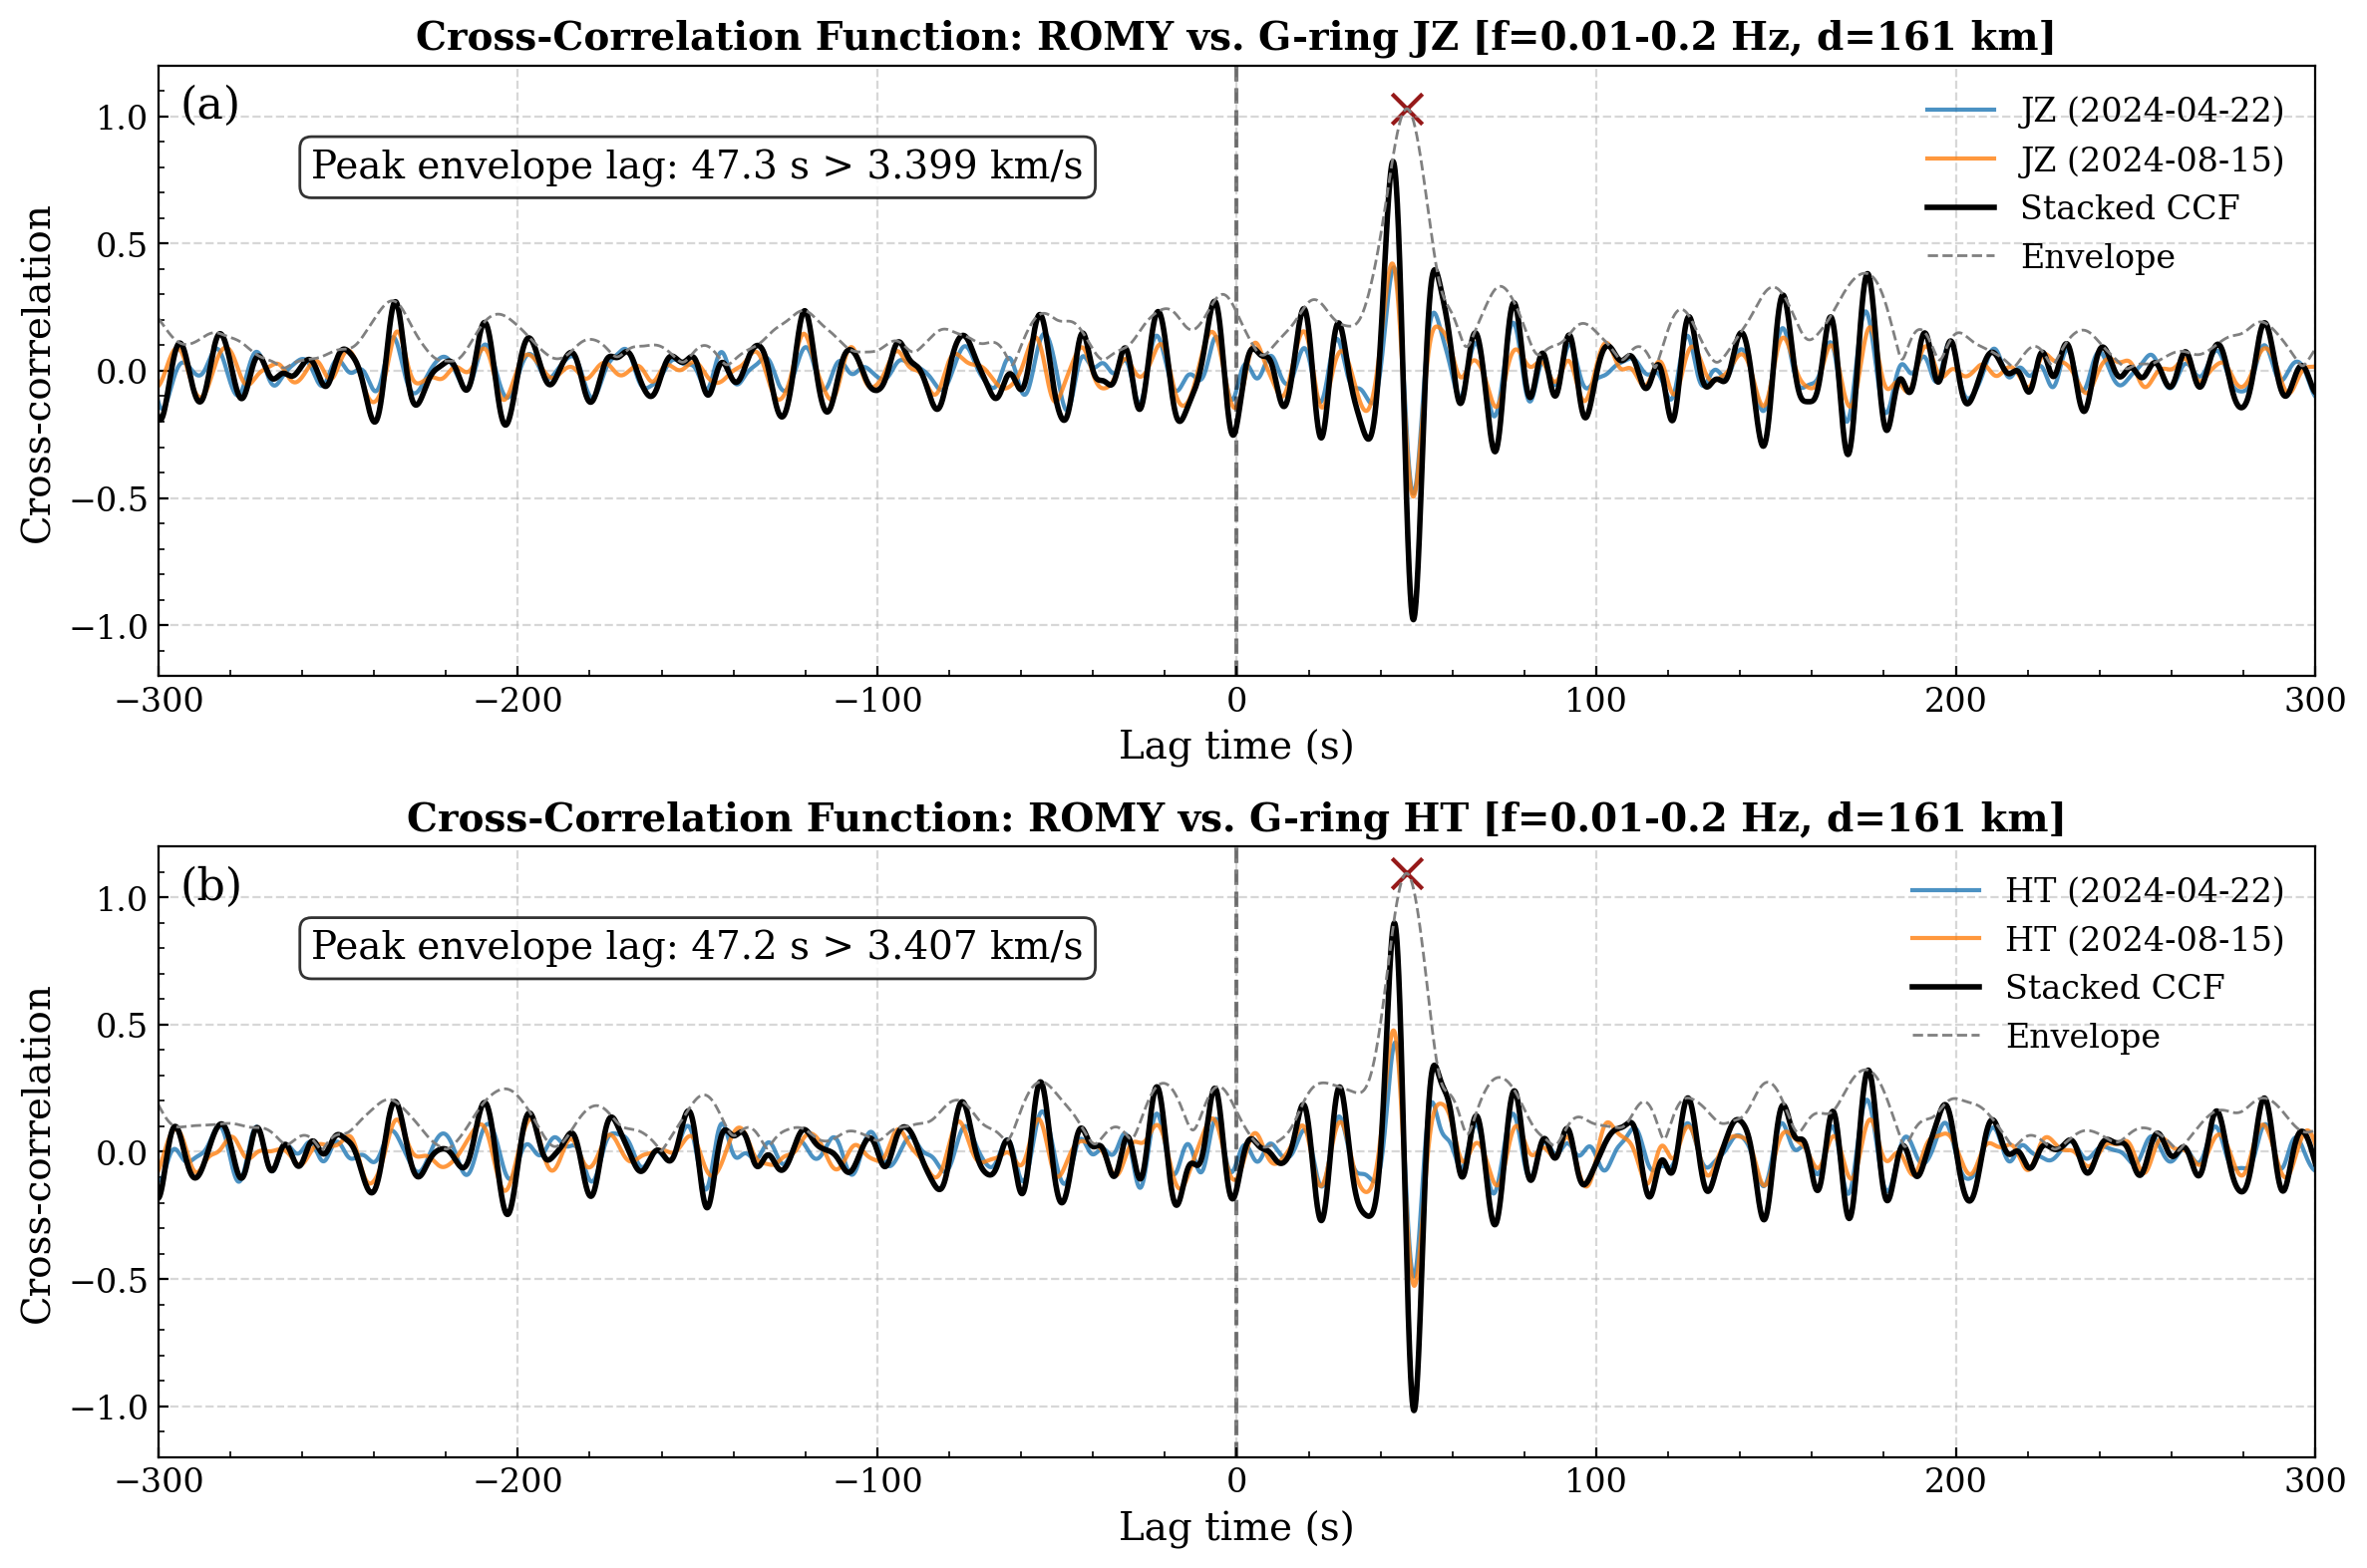

In [40]:
os.makedirs("./output/figures/ccf", exist_ok=True)
# Create figure with 2 rows
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

date_labels = [d[:4]+"-"+d[4:6]+"-"+d[6:] for d in dates]

# Top subplot: JZ cross-correlation
ax1 = axes[0]
ax1.plot(lags1_jz, cc1_jz, 'tab:blue', linewidth=1.5, alpha=0.8, label=f'JZ ({date_labels[0]})')
ax1.plot(lags2_jz, cc2_jz, 'tab:orange', linewidth=1.5, alpha=0.8, label=f'JZ ({date_labels[1]})')
ax1.plot(lags1_jz, stack_jz, 'k-', linewidth=2, label='Stacked CCF')
ax1.axvline(0, color='k', linestyle='--', linewidth=1.5, alpha=0.5)

env_jz = np.abs(hilbert(stack_jz))
max_env_idx = env_jz.argmax()
ax1.plot(lags1_jz, env_jz, c='gray', ls="--", linewidth=1, label='Envelope')
ax1.scatter(lags1_jz[max_env_idx], env_jz[max_env_idx], color='darkred', marker='x', s=120, alpha=0.9, zorder=1)
ax1.text(-150, 0.8, f'Peak envelope lag: {lags1_jz[max_env_idx]:.1f} s > {dist_km/lags1_jz[max_env_idx]:.3f} km/s',
        fontsize=14, ha='center', va='center', color='k', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax1.set_xlabel('Lag time (s)', fontsize=14)
ax1.set_ylabel('Cross-correlation', fontsize=14)
ax1.set_title(f'Cross-Correlation Function: ROMY vs. G-ring JZ [f={fmin}-{fmax} Hz, d={dist_km:.0f} km]', fontsize=14, fontweight='bold')
ax1.set_xlim(-300, 300)
ax1.set_ylim(-1.2, 1.2)
ax1.grid(True, alpha=0.5, linestyle='--')
ax1.legend(fontsize=12, loc=1)
ax1.tick_params(labelsize=12)
ax1.text(0.01, 0.97, "(a)", transform=ax1.transAxes, fontsize=16, ha='left', va='top')

# Bottom subplot: HT cross-correlation
ax2 = axes[1]
ax2.plot(lags1_ht, cc1_ht, 'tab:blue', linewidth=1.5, alpha=0.8, label=f'HT ({date_labels[0]})')
ax2.plot(lags2_ht, cc2_ht, 'tab:orange', linewidth=1.5, alpha=0.8, label=f'HT ({date_labels[1]})')
ax2.plot(lags1_ht, stack_ht, 'k-', linewidth=2, label='Stacked CCF')
ax2.axvline(0, color='k', linestyle='--', linewidth=1.5, alpha=0.5)

env_ht = np.abs(hilbert(stack_ht))
max_env_idx = env_ht.argmax()
ax2.plot(lags1_ht, env_ht, c='gray', ls="--", linewidth=1, label='Envelope')
ax2.scatter(lags1_ht[max_env_idx], env_ht[max_env_idx], color='darkred', marker='x', s=120, alpha=0.9, zorder=1)
ax2.text(-150, 0.8, f'Peak envelope lag: {lags1_ht[max_env_idx]:.1f} s > {dist_km/lags1_ht[max_env_idx]:.3f} km/s',
        fontsize=14, ha='center', va='center', color='k', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax2.set_xlabel('Lag time (s)', fontsize=14)
ax2.set_ylabel('Cross-correlation', fontsize=14)
ax2.set_title(f'Cross-Correlation Function: ROMY vs. G-ring HT [f={fmin}-{fmax} Hz, d={dist_km:.0f} km]', fontsize=14, fontweight='bold')
ax2.set_xlim(-300, 300)
ax2.set_ylim(-1.2, 1.2)
ax2.grid(True, alpha=0.5, linestyle='--')
ax2.legend(fontsize=12, loc=1)
ax2.tick_params(labelsize=12)
ax2.text(0.01, 0.97, "(b)", transform=ax2.transAxes, fontsize=16, ha='left', va='top')

plt.tight_layout()
plt.show()

fig.savefig(f'./output/figures/ccf/cross_correlation_romy_gring.png', dpi=300, bbox_inches='tight')


maximum of product: 0.99


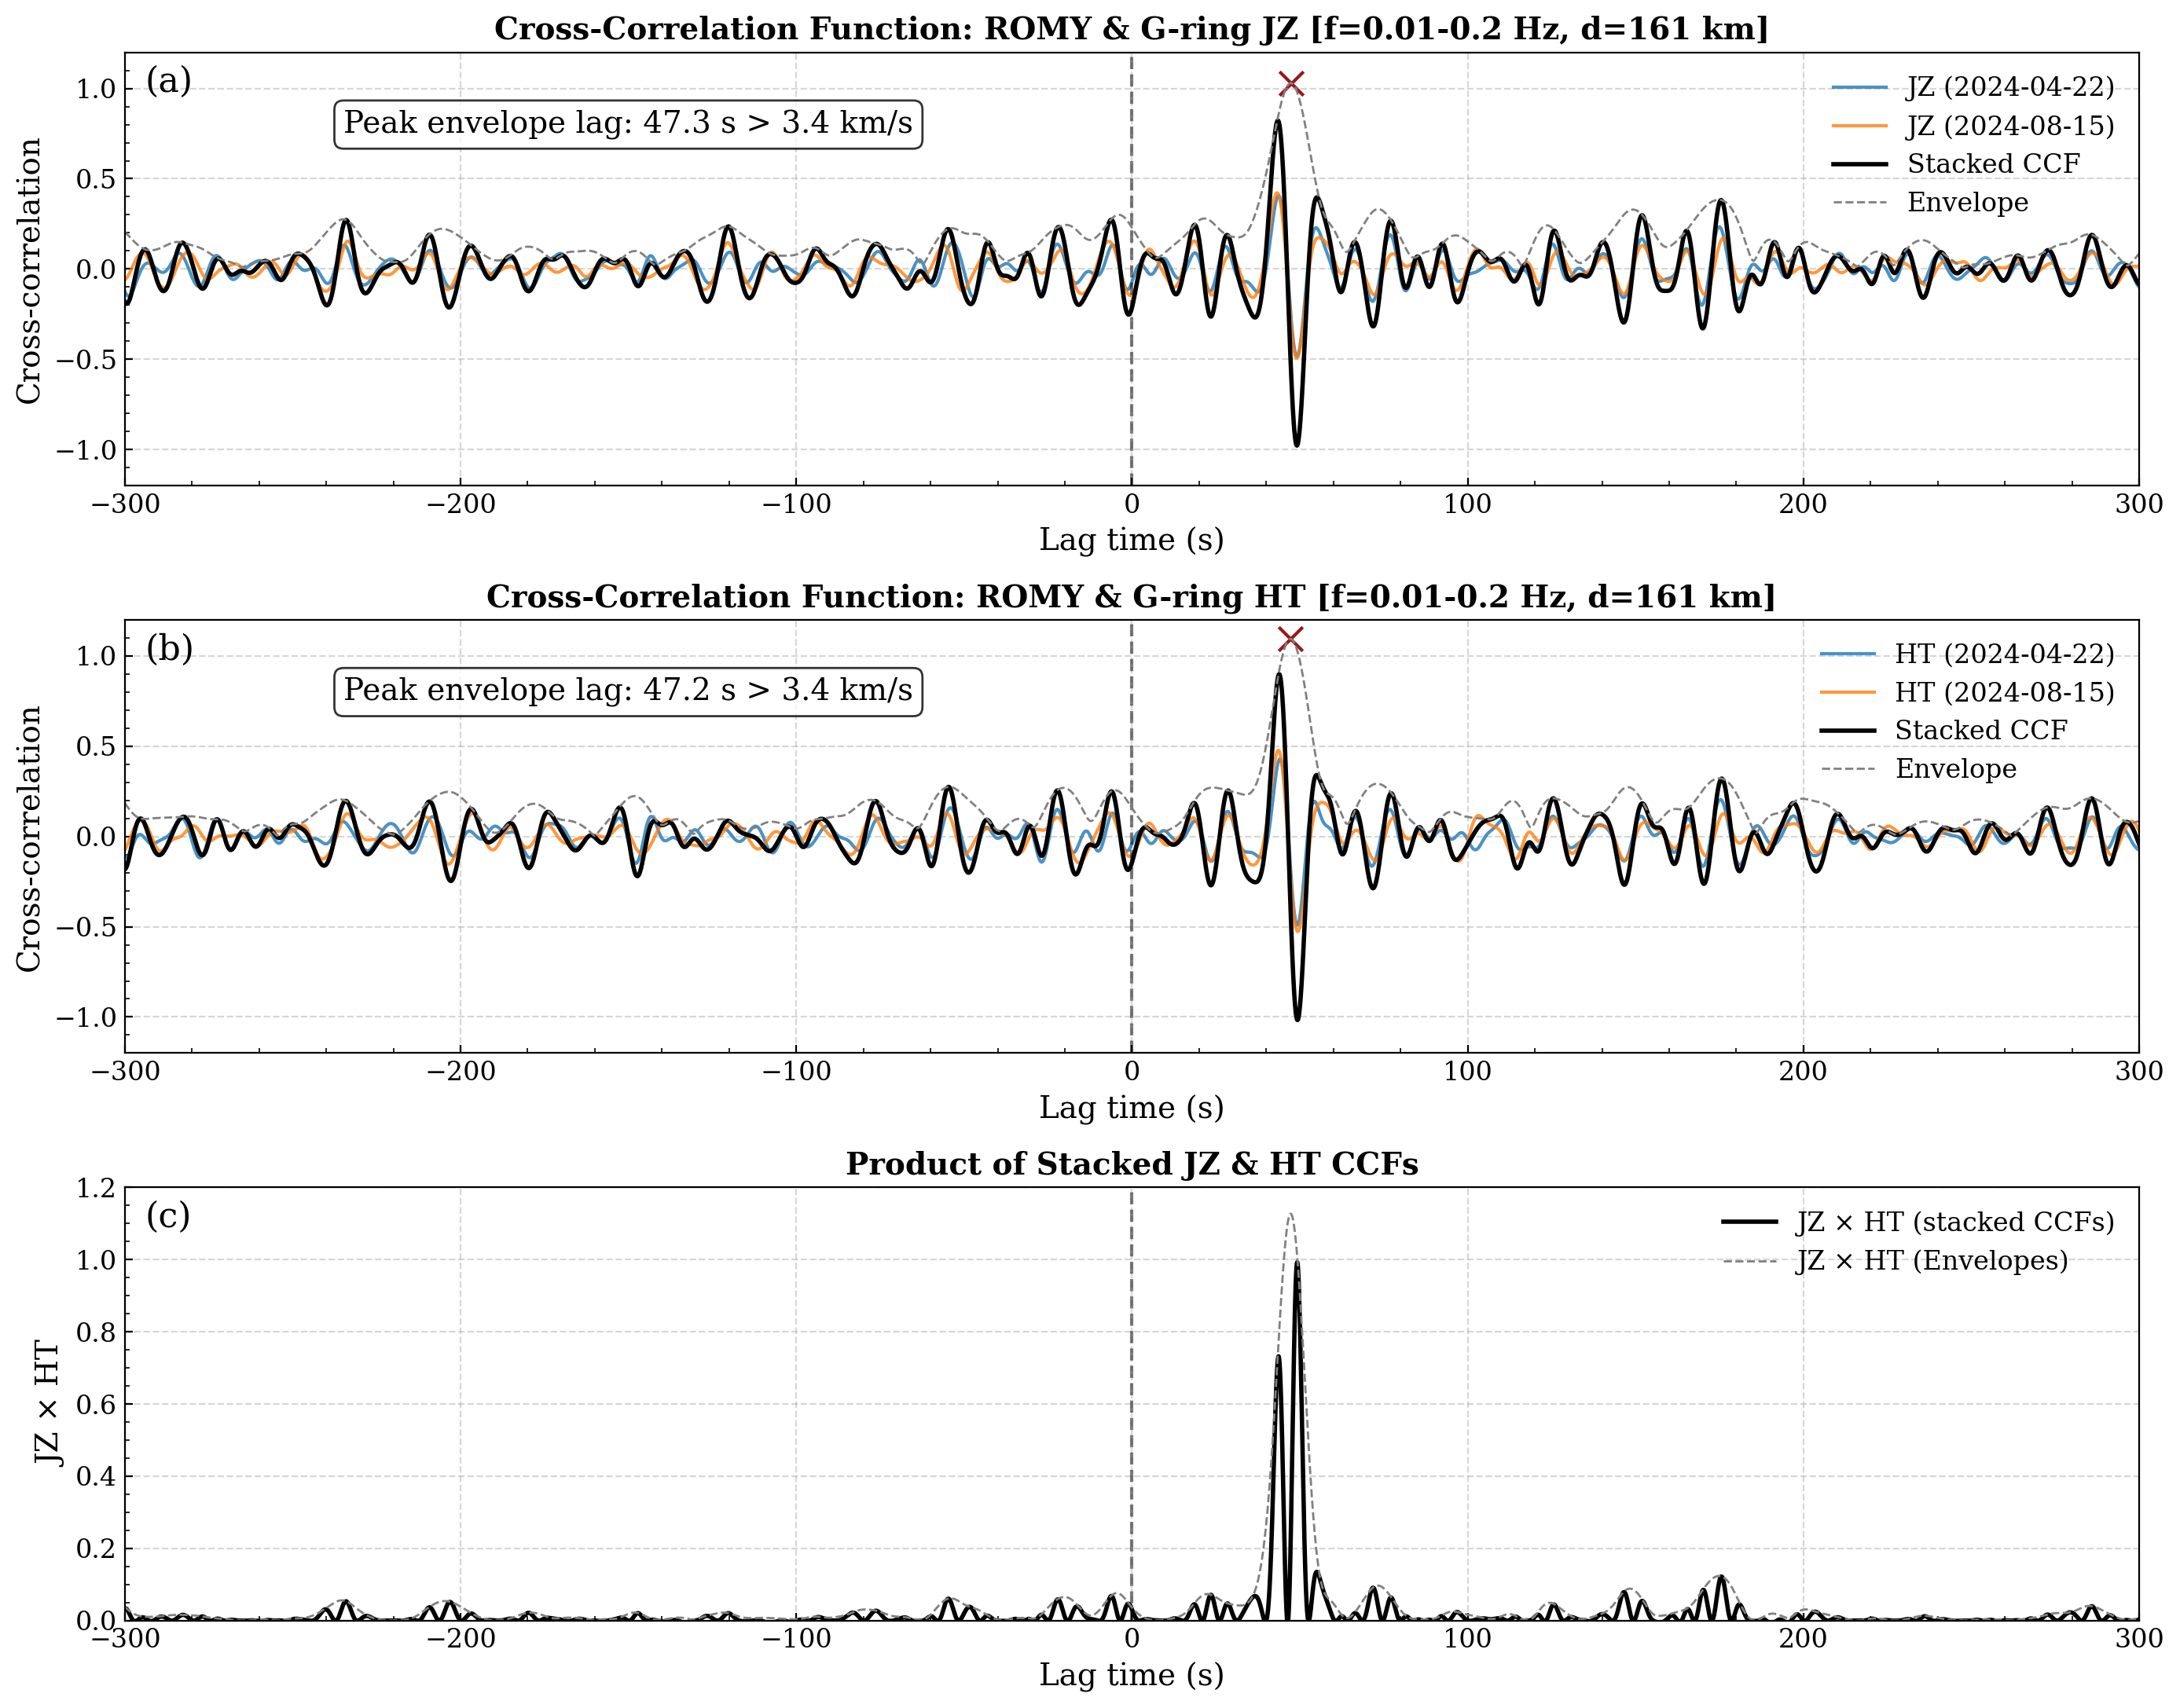

In [41]:
os.makedirs("./output/figures/ccf", exist_ok=True)
# Create figure with 3 rows
fig, axes = plt.subplots(3, 1, figsize=(14, 11))

date_labels = [d[:4]+"-"+d[4:6]+"-"+d[6:] for d in dates]

# Top subplot: JZ cross-correlation
ax1 = axes[0]
ax1.plot(lags1_jz, cc1_jz, 'tab:blue', linewidth=1.5, alpha=0.8, label=f'JZ ({date_labels[0]})')
ax1.plot(lags2_jz, cc2_jz, 'tab:orange', linewidth=1.5, alpha=0.8, label=f'JZ ({date_labels[1]})')
ax1.plot(lags1_jz, stack_jz, 'k-', linewidth=2, label='Stacked CCF')
ax1.axvline(0, color='k', linestyle='--', linewidth=1.5, alpha=0.5)

env_jz = np.abs(hilbert(stack_jz))
max_env_idx = env_jz.argmax()
ax1.plot(lags1_jz, env_jz, c='gray', ls="--", linewidth=1, label='Envelope')
ax1.scatter(lags1_jz[max_env_idx], env_jz[max_env_idx], color='darkred', marker='x', s=120, alpha=0.9, zorder=1)
ax1.text(-150, 0.8, f'Peak envelope lag: {lags1_jz[max_env_idx]:.1f} s > {dist_km/lags1_jz[max_env_idx]:.1f} km/s',
        fontsize=14, ha='center', va='center', color='k', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax1.set_xlabel('Lag time (s)', fontsize=14)
ax1.set_ylabel('Cross-correlation', fontsize=14)
ax1.set_title(f'Cross-Correlation Function: ROMY & G-ring JZ [f={fmin}-{fmax} Hz, d={dist_km:.0f} km]', fontsize=14, fontweight='bold')
ax1.set_xlim(-300, 300)
ax1.set_ylim(-1.2, 1.2)
ax1.grid(True, alpha=0.5, linestyle='--')
ax1.legend(fontsize=12, loc=1)
ax1.tick_params(labelsize=12)
ax1.text(0.01, 0.97, "(a)", transform=ax1.transAxes, fontsize=16, ha='left', va='top')

# Middle subplot: HT cross-correlation
ax2 = axes[1]
ax2.plot(lags1_ht, cc1_ht, 'tab:blue', linewidth=1.5, alpha=0.8, label=f'HT ({date_labels[0]})')
ax2.plot(lags2_ht, cc2_ht, 'tab:orange', linewidth=1.5, alpha=0.8, label=f'HT ({date_labels[1]})')
ax2.plot(lags1_ht, stack_ht, 'k-', linewidth=2, label='Stacked CCF')
ax2.axvline(0, color='k', linestyle='--', linewidth=1.5, alpha=0.5)

env_ht = np.abs(hilbert(stack_ht))
max_env_idx = env_ht.argmax()
ax2.plot(lags1_ht, env_ht, c='gray', ls="--", linewidth=1, label='Envelope')
ax2.scatter(lags1_ht[max_env_idx], env_ht[max_env_idx], color='darkred', marker='x', s=120, alpha=0.9, zorder=1)
ax2.text(-150, 0.8, f'Peak envelope lag: {lags1_ht[max_env_idx]:.1f} s > {dist_km/lags1_ht[max_env_idx]:.1f} km/s',
        fontsize=14, ha='center', va='center', color='k', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax2.set_xlabel('Lag time (s)', fontsize=14)
ax2.set_ylabel('Cross-correlation', fontsize=14)
ax2.set_title(f'Cross-Correlation Function: ROMY & G-ring HT [f={fmin}-{fmax} Hz, d={dist_km:.0f} km]', fontsize=14, fontweight='bold')
ax2.set_xlim(-300, 300)
ax2.set_ylim(-1.2, 1.2)
ax2.grid(True, alpha=0.5, linestyle='--')
ax2.legend(fontsize=12, loc=1)
ax2.tick_params(labelsize=12)
ax2.text(0.01, 0.97, "(b)", transform=ax2.transAxes, fontsize=16, ha='left', va='top')

# Bottom subplot: product of stacked JZ and HT CCFs
ax3 = axes[2]
ax3.plot(lags1_jz, prod_stack_jz_ht, 'k-', linewidth=2, label='JZ × HT (stacked CCFs)')
ax3.axvline(0, color='k', linestyle='--', linewidth=1.5, alpha=0.5)

print("maximum of product:", round(np.max(prod_stack_jz_ht), 2))

env_prod = env_jz * env_ht
ax3.plot(lags1_jz, env_prod, c='gray', ls="--", linewidth=1, label='JZ × HT (Envelopes)')

ax3.set_xlabel('Lag time (s)', fontsize=14)
ax3.set_ylabel('JZ × HT', fontsize=14)
ax3.set_title(f'Product of Stacked JZ & HT CCFs', fontsize=14, fontweight='bold')
ax3.set_xlim(-300, 300)
ax3.set_ylim(0, 1.2)
ax3.grid(True, alpha=0.5, linestyle='--')
ax3.legend(fontsize=12, loc=1)
ax3.tick_params(labelsize=12)
ax3.text(0.01, 0.97, "(c)", transform=ax3.transAxes, fontsize=16, ha='left', va='top')

plt.tight_layout()
plt.show()

# fig.savefig(f'./output/figures/ccf/cross_correlation_romy_gring.png', dpi=300, bbox_inches='tight')


## Publication Figure

In [42]:
# Publication-style defaults
plt.rcParams.update({
    "font.size": 11,
    "font.family": "serif",
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "ytick.minor.visible": True,
    "xtick.minor.visible": True,
    "legend.frameon": False,
    "figure.dpi": 200,
})

maximum of cc_stack: 0.89


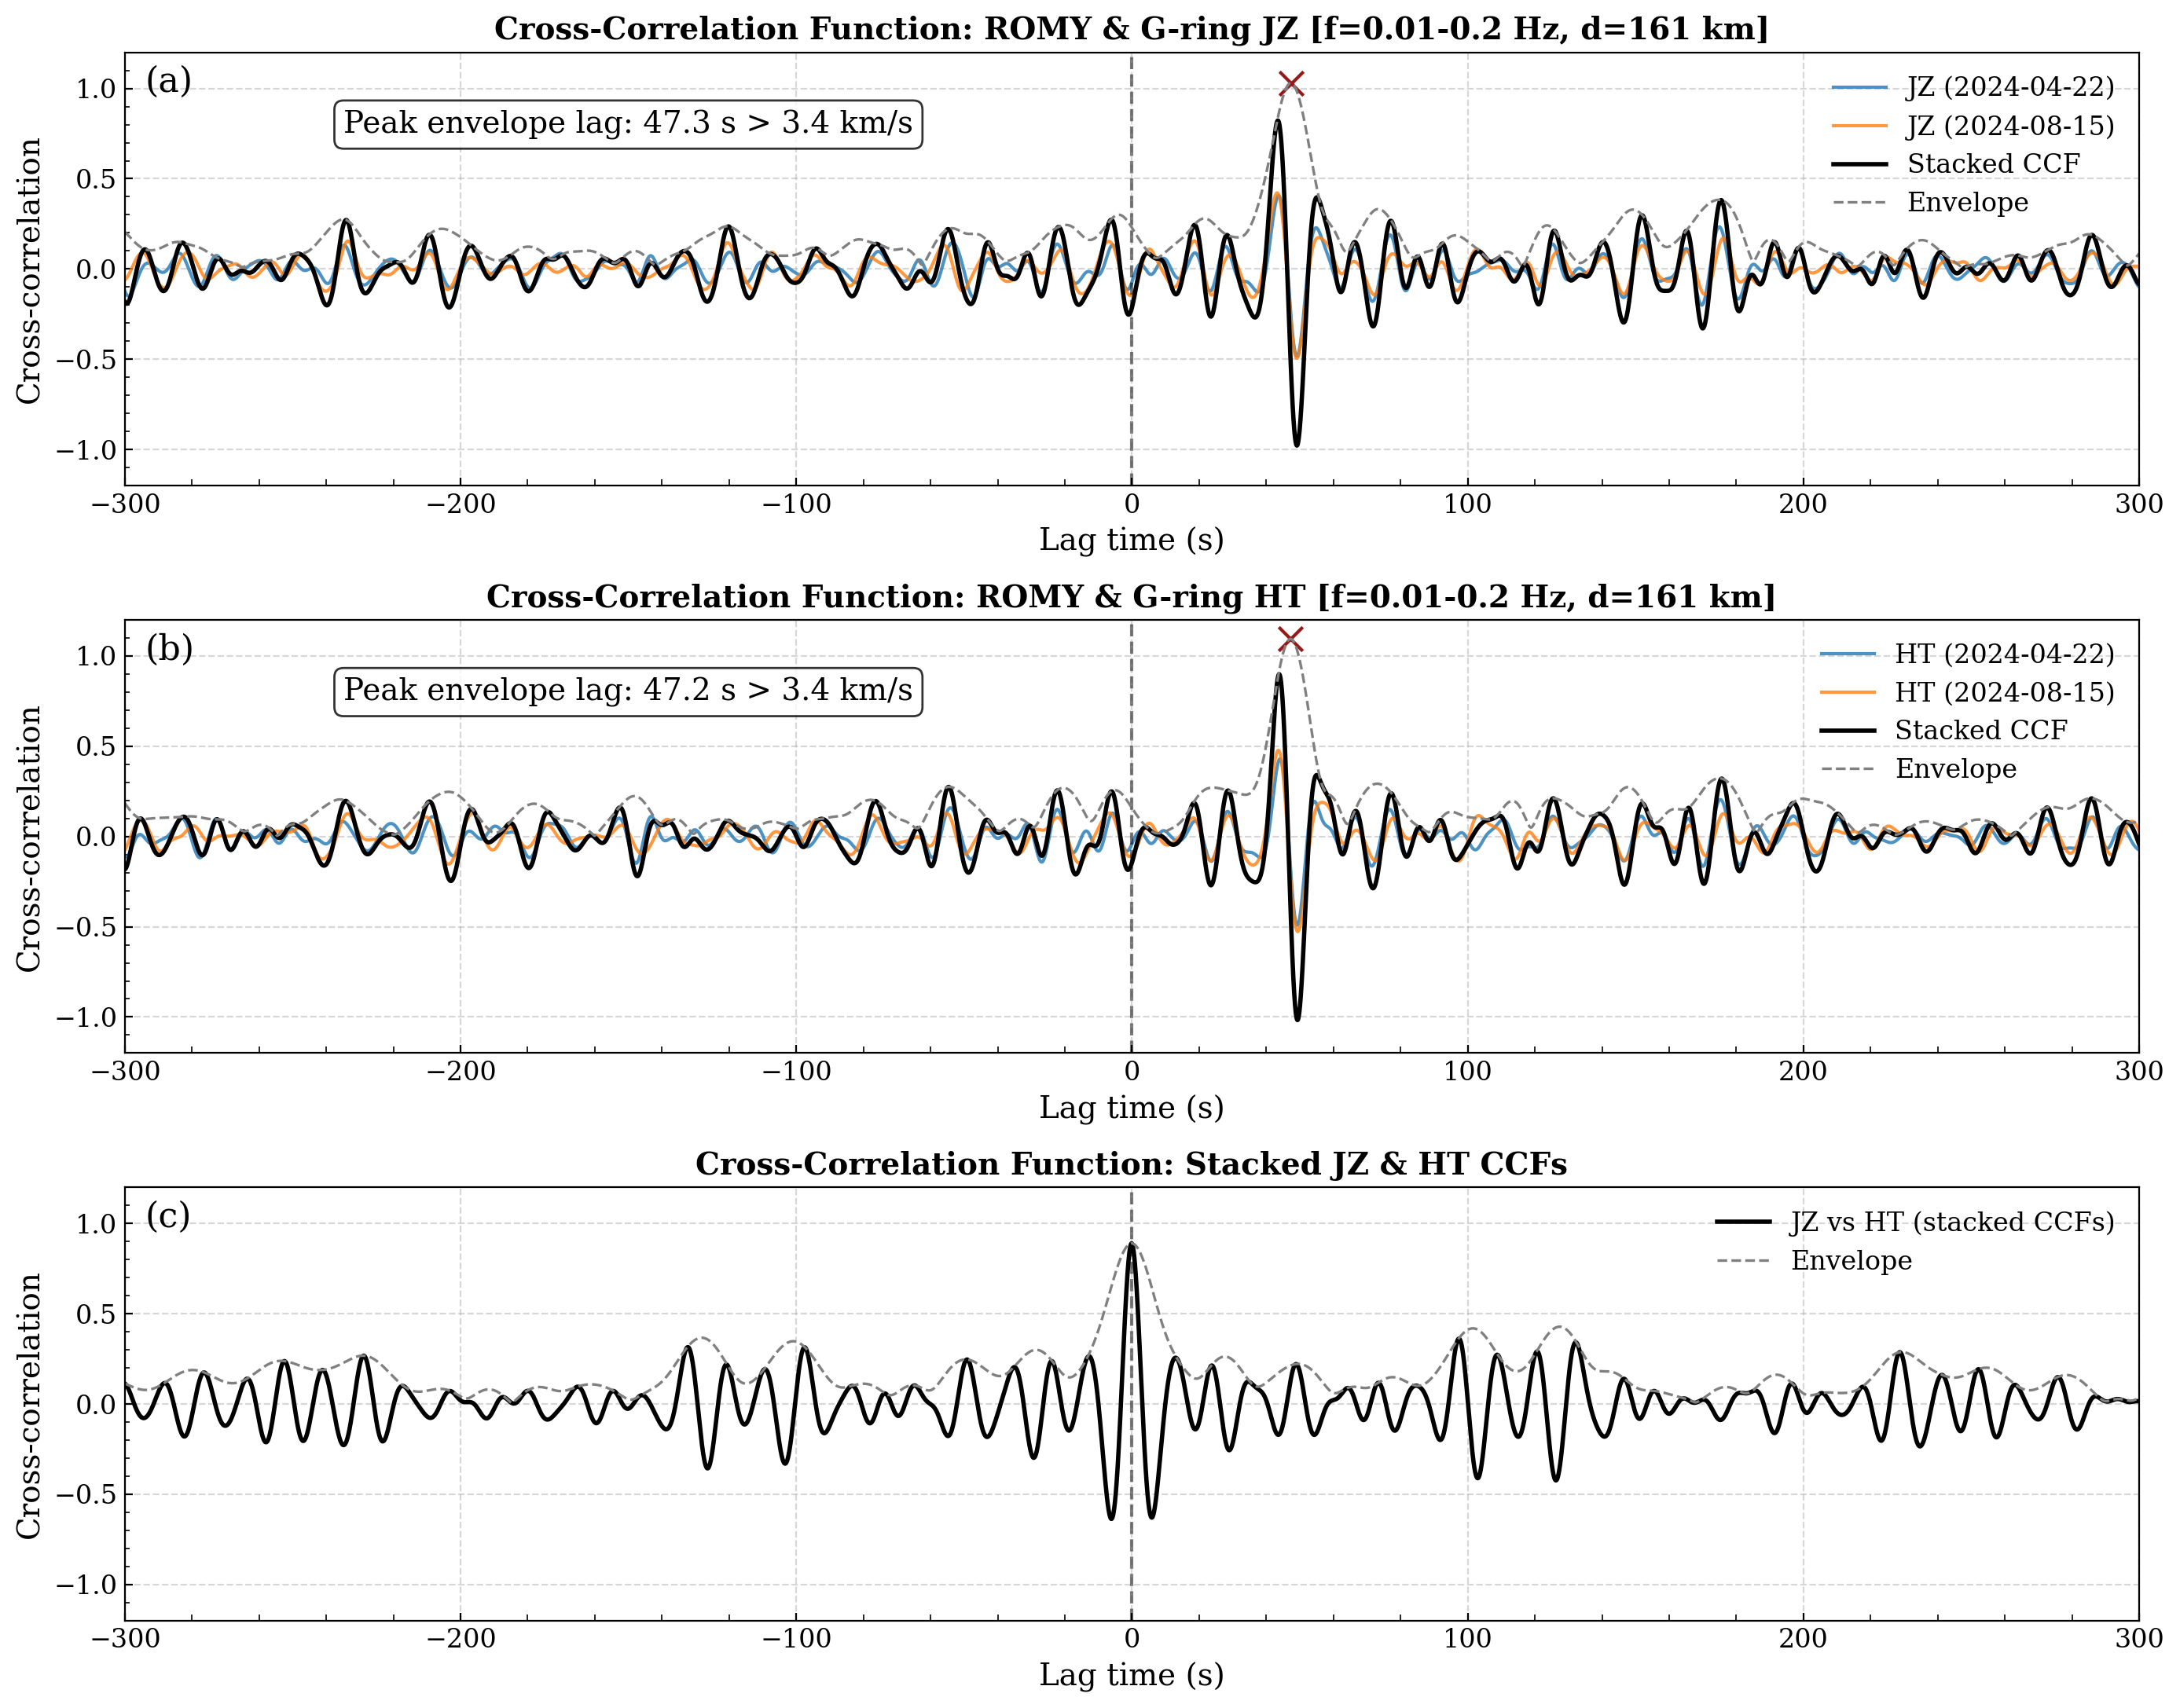

In [43]:
os.makedirs("./output/figures/publication", exist_ok=True)
# Create figure with 3 rows
fig, axes = plt.subplots(3, 1, figsize=(14, 11))

date_labels = [d[:4]+"-"+d[4:6]+"-"+d[6:] for d in dates]

# Top subplot: JZ cross-correlation
ax1 = axes[0]
ax1.plot(lags1_jz, cc1_jz, 'tab:blue', linewidth=1.5, alpha=0.8, label=f'JZ ({date_labels[0]})')
ax1.plot(lags2_jz, cc2_jz, 'tab:orange', linewidth=1.5, alpha=0.8, label=f'JZ ({date_labels[1]})')
ax1.plot(lags1_jz, stack_jz, 'k-', linewidth=2, label='Stacked CCF')
ax1.axvline(0, color='k', linestyle='--', linewidth=1.5, alpha=0.5)

env_jz = np.abs(hilbert(stack_jz))
max_env_idx = env_jz.argmax()
ax1.plot(lags1_jz, env_jz, c='gray', ls="--", linewidth=1.2, label='Envelope')
ax1.scatter(lags1_jz[max_env_idx], env_jz[max_env_idx], color='darkred', marker='x', s=120, alpha=0.9, zorder=1)
ax1.text(-150, 0.8, f'Peak envelope lag: {lags1_jz[max_env_idx]:.1f} s > {dist_km/lags1_jz[max_env_idx]:.1f} km/s',
        fontsize=14, ha='center', va='center', color='k', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax1.set_xlabel('Lag time (s)', fontsize=14)
ax1.set_ylabel('Cross-correlation', fontsize=14)
ax1.set_title(f'Cross-Correlation Function: ROMY & G-ring JZ [f={fmin}-{fmax} Hz, d={dist_km:.0f} km]', fontsize=14, fontweight='bold')
ax1.set_xlim(-300, 300)
ax1.set_ylim(-1.2, 1.2)
ax1.grid(True, alpha=0.5, linestyle='--')
ax1.legend(fontsize=12, loc=1)
ax1.tick_params(labelsize=12)
ax1.text(0.01, 0.97, "(a)", transform=ax1.transAxes, fontsize=16, ha='left', va='top')

# Middle subplot: HT cross-correlation
ax2 = axes[1]
ax2.plot(lags1_ht, cc1_ht, 'tab:blue', linewidth=1.5, alpha=0.8, label=f'HT ({date_labels[0]})')
ax2.plot(lags2_ht, cc2_ht, 'tab:orange', linewidth=1.5, alpha=0.8, label=f'HT ({date_labels[1]})')
ax2.plot(lags1_ht, stack_ht, 'k-', linewidth=2, label='Stacked CCF')
ax2.axvline(0, color='k', linestyle='--', linewidth=1.5, alpha=0.5)

env_ht = np.abs(hilbert(stack_ht))
max_env_idx = env_ht.argmax()
ax2.plot(lags1_ht, env_ht, c='gray', ls="--", linewidth=1.2, label='Envelope')
ax2.scatter(lags1_ht[max_env_idx], env_ht[max_env_idx], color='darkred', marker='x', s=120, alpha=0.9, zorder=1)
ax2.text(-150, 0.8, f'Peak envelope lag: {lags1_ht[max_env_idx]:.1f} s > {dist_km/lags1_ht[max_env_idx]:.1f} km/s',
        fontsize=14, ha='center', va='center', color='k', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax2.set_xlabel('Lag time (s)', fontsize=14)
ax2.set_ylabel('Cross-correlation', fontsize=14)
ax2.set_title(f'Cross-Correlation Function: ROMY & G-ring HT [f={fmin}-{fmax} Hz, d={dist_km:.0f} km]', fontsize=14, fontweight='bold')
ax2.set_xlim(-300, 300)
ax2.set_ylim(-1.2, 1.2)
ax2.grid(True, alpha=0.5, linestyle='--')
ax2.legend(fontsize=12, loc=1)
ax2.tick_params(labelsize=12)
ax2.text(0.01, 0.97, "(b)", transform=ax2.transAxes, fontsize=16, ha='left', va='top')

# Bottom subplot: cross-correlation of stacked JZ and HT CCFs
ax3 = axes[2]
lags_stack = ccross_stack_jz_ht['lags']
cc_stack = ccross_stack_jz_ht['correlation']
ax3.plot(lags_stack, cc_stack, 'k-', linewidth=2, label='JZ vs HT (stacked CCFs)')
ax3.axvline(0, color='k', linestyle='--', linewidth=1.5, alpha=0.5)

print("maximum of cc_stack:", round(np.max(cc_stack), 2))

env_stack = np.abs(hilbert(cc_stack))
max_env_idx = env_stack.argmax()
ax3.plot(lags_stack, env_stack, c='gray', ls="--", linewidth=1.2, label='Envelope')

ax3.set_xlabel('Lag time (s)', fontsize=14)
ax3.set_ylabel('Cross-correlation', fontsize=14)
ax3.set_title(f'Cross-Correlation Function: Stacked JZ & HT CCFs', fontsize=14, fontweight='bold')
ax3.set_xlim(-300, 300)
ax3.set_ylim(-1.2, 1.2)
ax3.grid(True, alpha=0.5, linestyle='--')
ax3.legend(fontsize=12, loc=1)
ax3.tick_params(labelsize=12)
ax3.text(0.01, 0.97, "(c)", transform=ax3.transAxes, fontsize=16, ha='left', va='top')

for ax in axes:
    ax.minorticks_on()
    ax.tick_params(axis='x', which='minor', length=3)

plt.tight_layout()
plt.show()

fig.savefig(f'./output/figures/publication/cross_correlation_romy_gring_v2.png', dpi=300, bbox_inches='tight')
